In [10]:
import itertools
import json
import sys
from pathlib import Path

import networkx as nx
import numpy as np

# Make imports robust whether the notebook runs from project root or notebooks/
project_root = Path.cwd().resolve()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.graph_dataset_preparation import ensure_unique_edge_weights
from src.graph_utils import compute_Q, ktte, kttw,plot_weighted_graphs


In [11]:
def load_graphs_from_json(path: Path) -> list[nx.Graph]:
    """Load toy graphs from JSON.

    Expected format:
    {
      "graphs": [
        {"name": "G1", "nodes": [...], "edges": [[u, v, weight], ...]},
        ...
      ]
    }
    """
    payload = json.loads(path.read_text(encoding="utf-8"))

    if isinstance(payload, dict):
        graph_specs = payload.get("graphs")
    elif isinstance(payload, list):
        graph_specs = payload
    else:
        raise ValueError("JSON must be a list or a dict containing 'graphs'.")

    if not isinstance(graph_specs, list):
        raise ValueError("Could not find a valid list of graph specifications.")

    graphs: list[nx.Graph] = []
    for idx, spec in enumerate(graph_specs, start=1):
        if not isinstance(spec, dict):
            raise ValueError(f"Graph entry at index {idx - 1} is not an object.")

        graph_name = str(spec.get("name", f"G{idx}"))
        nodes = spec.get("nodes", [])
        edges = spec.get("edges", [])

        if not isinstance(nodes, list) or not isinstance(edges, list):
            raise ValueError(f"Graph {graph_name!r} must define list fields 'nodes' and 'edges'.")

        graph = nx.Graph()
        graph.add_nodes_from(nodes)

        for edge in edges:
            if not isinstance(edge, (list, tuple)) or len(edge) != 3:
                raise ValueError(f"Graph {graph_name!r} has invalid edge {edge!r}; expected [u, v, weight].")
            u, v, w = edge
            graph.add_edge(u, v, weight=float(w))

        graph.graph["name"] = graph_name
        graphs.append(graph)

    return graphs


In [12]:
data_path = project_root / "notebooks" / "toy_graphs.json"

# 1) Load every graph from file
loaded_graphs = load_graphs_from_json(data_path)

# 2) Ensure unique weights within each graph
graphs = ensure_unique_edge_weights(loaded_graphs, epsilon=1e-8)

print(f"Loaded {len(graphs)} graphs from: {data_path}")
for i, graph in enumerate(graphs, start=1):
    name = graph.graph.get("name", f"G{i}")
    weights = [float(data["weight"]) for _, _, data in graph.edges(data=True)]
    print(f"\n{name}: |V|={graph.number_of_nodes()}, |E|={graph.number_of_edges()}")
    print(f"Unique weights: {len(weights) == len(set(weights))}")
    print(f"Weights: {sorted(weights)}")


Loaded 5 graphs from: /Users/gregorioperez/Documents/Maestria/Investigacion/graph_kernels/notebooks/toy_graphs.json

G1_grid_3x3_uniform: |V|=9, |E|=12
Unique weights: True
Weights: [1.0, 1.00000001, 1.00000002, 1.00000003, 1.00000004, 1.00000005, 1.00000006, 1.00000007, 1.00000008, 1.00000009, 1.0000001, 1.00000011]

G3_grid_3x3_1and15: |V|=9, |E|=12
Unique weights: True
Weights: [1.5, 1.50000001, 1.50000002, 1.50000003, 1.50000004, 1.50000005, 1.50000006, 1.50000007, 1.50000008, 1.50000009, 1.5000001, 1.50000011]

G3_grid_3x3_2: |V|=9, |E|=12
Unique weights: True
Weights: [2.0, 2.00000001, 2.00000002, 2.00000003, 2.00000004, 2.00000005, 2.00000006, 2.00000007, 2.00000008, 2.00000009, 2.0000001, 2.00000011]

G3_grid_3x3_2: |V|=9, |E|=12
Unique weights: True
Weights: [1.0, 1.00000001, 1.00000002, 1.00000003, 1.00000004, 1.00000005, 2.0, 2.00000001, 2.00000002, 2.00000003, 2.00000004, 2.00000005]

gridExtra: |V|=11, |E|=14
Unique weights: True
Weights: [2.0, 2.00000001, 2.00000002, 2.00

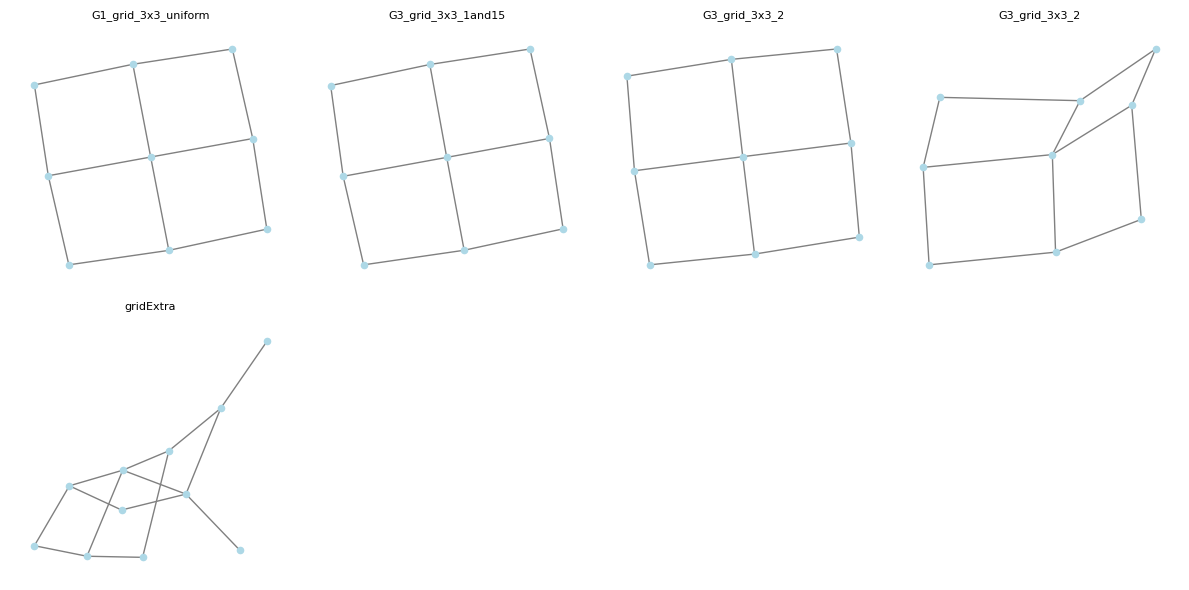

In [13]:
plot_weighted_graphs(graphs)

In [14]:
# 3) Plot all loaded graphs in a subplot layout driven by list length
titles = [g.graph.get("name", f"G{i + 1}") for i, g in enumerate(graphs)]


In [15]:
# 4) Compute every graph's Q matrix
Q_list = [compute_Q(graph, alpha=1) for graph in graphs]

'''
for i in range(len(Q_list)):
    frob = np.linalg.norm(Q_list[i], 'fro')
    if frob != 0:
        Q_list[i] = Q_list[i] / frob
'''
names = [graph.graph.get("name", f"G{i + 1}") for i, graph in enumerate(graphs)]

for name, Q in zip(names, Q_list):
    print(f"\n{name} -> Q shape: {Q.shape}")
    print(np.array2string(Q, precision=6, suppress_small=True))



G1_grid_3x3_uniform -> Q shape: (4, 4)
[[ 4. -1.  3. -1.]
 [-1.  4. -1.  3.]
 [ 3. -1.  6. -2.]
 [-1.  3. -2.  6.]]

G3_grid_3x3_1and15 -> Q shape: (4, 4)
[[ 6.  -1.5  4.5 -1.5]
 [-1.5  6.  -1.5  4.5]
 [ 4.5 -1.5  9.  -3. ]
 [-1.5  4.5 -3.   9. ]]

G3_grid_3x3_2 -> Q shape: (4, 4)
[[ 8. -2.  6. -2.]
 [-2.  8. -2.  6.]
 [ 6. -2. 12. -4.]
 [-2.  6. -4. 12.]]

G3_grid_3x3_2 -> Q shape: (4, 4)
[[ 4.  1.  0. -1.]
 [ 1.  6.  2.  2.]
 [ 0.  2.  8.  6.]
 [-1.  2.  6. 10.]]

gridExtra -> Q shape: (4, 4)
[[ 8. -2.  6. -2.]
 [-2.  8. -2.  6.]
 [ 6. -2. 12. -4.]
 [-2.  6. -4. 12.]]


In [16]:
# 5) Compute kernels between all loaded graphs
gamma = 0.1
n = len(Q_list)

kt_matrix = np.zeros((n, n), dtype=float)   # kt = ktte
ktw_matrix = np.zeros((n, n), dtype=float)  # ktw = kttw

for i in range(n):
    for j in range(n):
        kt_matrix[i, j] = ktte(Q_list[i], Q_list[j], gamma=gamma)
        ktw_matrix[i, j] = kttw(Q_list[i], Q_list[j], gamma=gamma)

print(f"gamma = {gamma}")
print("\nPairwise kernels (unique graph pairs):")
for i, j in itertools.combinations(range(n), 2):
    print(
        f"{names[i]} vs {names[j]} -> "
        f"kt=ktte={kt_matrix[i, j]:.8f}, "
        f"ktw=kttw={ktw_matrix[i, j]:.8f}"
    )

print("\nFull kt (ktte) matrix:")
print(np.array2string(kt_matrix, precision=6, suppress_small=True))

print("\nFull ktw (kttw) matrix:")
print(np.array2string(ktw_matrix, precision=6, suppress_small=True))


gamma = 0.1

Pairwise kernels (unique graph pairs):
G1_grid_3x3_uniform vs G3_grid_3x3_1and15 -> kt=ktte=0.02127974, ktw=kttw=0.90391449
G1_grid_3x3_uniform vs G3_grid_3x3_2 -> kt=ktte=0.00000021, ktw=kttw=0.70953480
G1_grid_3x3_uniform vs G3_grid_3x3_2 -> kt=ktte=0.00000000, ktw=kttw=0.49672680
G1_grid_3x3_uniform vs gridExtra -> kt=ktte=0.00000021, ktw=kttw=0.70953479
G3_grid_3x3_1and15 vs G3_grid_3x3_2 -> kt=ktte=0.02127974, ktw=kttw=0.93072003
G3_grid_3x3_1and15 vs G3_grid_3x3_2 -> kt=ktte=0.00000000, ktw=kttw=0.45923321
G3_grid_3x3_1and15 vs gridExtra -> kt=ktte=0.02127973, ktw=kttw=0.93072003
G3_grid_3x3_2 vs G3_grid_3x3_2 -> kt=ktte=0.00000000, ktw=kttw=0.36739360
G3_grid_3x3_2 vs gridExtra -> kt=ktte=1.00000000, ktw=kttw=1.00000000
G3_grid_3x3_2 vs gridExtra -> kt=ktte=0.00000000, ktw=kttw=0.36739360

Full kt (ktte) matrix:
[[1.      0.02128 0.      0.      0.     ]
 [0.02128 1.      0.02128 0.      0.02128]
 [0.      0.02128 1.      0.      1.     ]
 [0.      0.      0.      1